# D14 独立练习

本次全部为模拟价格。先写预期再运行，右上角选Python (D Learning)。
Shift+Enter运行、Ctrl+S保存。逐行参考在reference.ipynb；最后关闭参考独立完成。


## 1. 手算累计收益

先在纸上算100→110→99；再用两条收益[.1,-.1]计算价值倍数和累计连乘。解释为什么不是简单相加。


In [6]:
import pandas as pd  # pandas表格处理库，简称pd

demo_returns = pd.Series([0.10, -0.10], name="period_return")  # 两段已知收益，小数形式
demo_factors = 1 + demo_returns  # 每段价值倍数：1.10、0.90
demo_wealth = demo_factors.cumprod(skipna=False)  # cumprod累计连乘，得到1.10、0.99
demo_cumulative = demo_wealth - 1  # 净值倍数减1，得到累计收益0.10、-0.01

print(demo_returns.sum())  # 简单相加为0，不能替代两段累计收益
print(demo_wealth)  # 查看每段结束时的价值倍数
print(demo_cumulative)  # 查看每段结束时的累计收益
print(f"两段累计收益：{demo_cumulative.iloc[-1]:.2%}")  # 预计-1.00%；.iloc[-1]取最后一个结果


0.0
0    1.10
1    0.99
Name: period_return, dtype: float64
0    0.10
1   -0.01
Name: period_return, dtype: float64
两段累计收益：-1.00%


## 2. 读取与检查

读取D14/data/prices.csv，转换日期与数值，检查空值、重复键和非正价格，再按asset/date排序。预计(12,3)。


In [34]:
from pathlib import Path
import pandas as pd


base_dir = Path("D:/Learning/study/d14")
raw = pd.read_csv(base_dir/"data"/"prices.csv")

raw["date"] = pd.to_datetime(
    prices["date"],
    format = "%Y-%m-%d",
    errors = "coerce",
)
raw["price"] = pd.to_numeric(
    prices["price"],
    errors = "coerce",
)
empty = raw.isna().sum()
print(empty)
print(raw.shape)

duplicated_key = raw.duplicated(subset = ["asset","price","date"],keep = False)
print(duplicated_key)

assert raw[["asset","date","price"]].notna().all().all()
assert not duplicated_key.any()
assert (raw["price"] > 0).all()

line = raw.sort_values(["asset","date"]).reset_index(drop=True)
print(line)
print(prices)

asset    0
date     0
price    0
dtype: int64
(12, 3)
0     False
1     False
2     False
3     False
4     False
5     False
6     False
7     False
8     False
9     False
10    False
11    False
dtype: bool
   asset       date  price
0      A 2026-10-12    100
1      A 2026-10-13    110
2      A 2026-10-14     99
3      A 2026-10-15    105
4      A 2026-10-16    102
5      A 2026-10-19    108
6      B 2026-10-12    200
7      B 2026-10-13    190
8      B 2026-10-14    209
9      B 2026-10-15    205
10     B 2026-10-16    210
11     B 2026-10-19    215
   asset       date  price  return_pct  growth_factor
0      A 2026-10-12    200         NaN       1.000000
1      A 2026-10-13    110   -0.450000       0.550000
2      A 2026-10-14    209    0.900000       1.900000
3      A 2026-10-15    105   -0.497608       0.502392
4      A 2026-10-16    102   -0.028571       0.971429
5      A 2026-10-16    210    1.058824       2.058824
6      B 2026-10-12    100         NaN       1.000000
7      

## 3. 收益与累计起点

组内pct_change(fill_method=None)，保留组首NaN。另建growth_factor=1+r，仅各资产首行设1。解释这与把首日真实收益填0的区别。


In [59]:
# 原始收益首行应该是什么：
# 累计指标的起始倍数是什么：
# 在这里计算收益与growth_factor。

line["pct_change"] = line.groupby("asset")["price"].pct_change(
    fill_method = None,
)
line["growth_factor"] = line["pct_change"] + 1

first_in_asset = line.groupby("asset").cumcount() ==0
line.loc[first_in_asset, "growth_factor"] = 1.0
# 把各资产第一行的累计起始倍数设为1。

print(line[["asset","date","price","pct_change","growth_factor"]])



   asset       date  price  pct_change  growth_factor
0      A 2026-10-12    100         NaN       1.000000
1      A 2026-10-13    110    0.100000       1.100000
2      A 2026-10-14     99   -0.100000       0.900000
3      A 2026-10-15    105    0.060606       1.060606
4      A 2026-10-16    102   -0.028571       0.971429
5      A 2026-10-19    108    0.058824       1.058824
6      B 2026-10-12    200         NaN       1.000000
7      B 2026-10-13    190   -0.050000       0.950000
8      B 2026-10-14    209    0.100000       1.100000
9      B 2026-10-15    205   -0.019139       0.980861
10     B 2026-10-16    210    0.024390       1.024390
11     B 2026-10-19    215    0.023810       1.023810


## 4. 组内累计连乘与核对

按资产cumprod(skipna=False)，得到wealth_index，再减1得到cumulative_return。用当前价格/本组首价-1核对。A第三期-1%，末期8%，B末期7.5%。


In [61]:
# A第三期累计收益：
# A/B末期累计收益：
# 在这里完成两种计算与误差核对。
line["wealth_index"] = line.groupby("asset")["growth_factor"].cumprod(
    skipna=False,
)
line["cumulative_return"] = line["wealth_index"] - 1

first_price = line.groupby("asset")["price"].transform("first")
line["return_from_price"] = line["price"] / first_price - 1 

maximum_error = (line["cumulative_return"] - line["return_from_price"]).abs().max()  



 # 计算最大绝对误差
print("两种累计计算的最大差异：", maximum_error)  # 预计为0或极小浮点误差
assert maximum_error < 1e-10  # 1e-10表示10的负10次方，用作本例核对容差

print(prices[["asset", "date", "wealth_index", "cumulative_return", "return_from_price"]])  # A第三期为-1%，末期8%；B末期7.5%


两种累计计算的最大差异： 2.220446049250313e-16
   asset       date  wealth_index  cumulative_return  return_from_price
0      A 2026-10-12         1.000              0.000              0.000
1      A 2026-10-13         0.550             -0.450             -0.450
2      A 2026-10-14         1.045              0.045              0.045
3      A 2026-10-15         0.525             -0.475             -0.475
4      A 2026-10-16         0.510             -0.490             -0.490
5      A 2026-10-16         1.050              0.050              0.050
6      B 2026-10-12         1.000              0.000              0.000
7      B 2026-10-13         1.900              0.900              0.900
8      B 2026-10-14         0.990             -0.010             -0.010
9      B 2026-10-15         2.050              1.050              1.050
10     B 2026-10-19         1.080              0.080              0.080
11     B 2026-10-19         2.150              1.150              1.150


## 5. 四行滚动例子

对100/110/99/105计算rolling(window=3,min_periods=3).mean()。先手算第三、第四条。


In [62]:
# 前两项为什么缺失：
# 第三项均价：
# 第四项均价：
# 在这里写小例子。
demo_prices = pd.Series([100, 110, 99, 105], name="price")  # 用四条价格观察窗口如何移动
demo_ma3 = demo_prices.rolling(  # rolling创建滚动窗口
    window=3,  # 每个窗口取最近三条观测
    min_periods=3,  # 至少三个非空价格才输出结果
).mean()  # 对每个窗口求算术平均数

print(demo_ma3)  # 预计NaN、NaN、103、104.6667


0           NaN
1           NaN
2    103.000000
3    104.666667
Name: price, dtype: float64


## 6. 各资产MA3

组内transform(lambda s:s.rolling(window=3,min_periods=3).mean())，解释s是什么以及结果为什么仍是12行。每组前两条缺失，共4个NaN。


In [69]:
# s代表什么：
# 预计缺失总数：
# 在这里计算ma3。
line["ma3"] = line.groupby("asset")["price"].transform(  # 分资产计算，并保持与原行对齐
    lambda s: s.rolling(window=3, min_periods=3).mean()  # s是一组价格；滚动三条后求每个窗口的均值
)  # 返回的每一条均价放到对应的资产和日期行

print(line[["asset", "date", "price", "ma3"]])  # 检查每个资产前两行都为NaN
print("均价缺失总数：", int(prices["ma3"].isna().sum()))  # 预计4，A/B各2条


   asset       date  price         ma3
0      A 2026-10-12    100         NaN
1      A 2026-10-13    110         NaN
2      A 2026-10-14     99  103.000000
3      A 2026-10-15    105  104.666667
4      A 2026-10-16    102  102.000000
5      A 2026-10-19    108  105.000000
6      B 2026-10-12    200         NaN
7      B 2026-10-13    190         NaN
8      B 2026-10-14    209  199.666667
9      B 2026-10-15    205  201.333333
10     B 2026-10-16    210  208.000000
11     B 2026-10-19    215  210.000000
均价缺失总数： 4


## 7. 累计收益图

在同一张图画A/B累计收益，纵轴按百分数显示，带标题、坐标轴说明、图例，保存outputs/cumulative_returns.png。


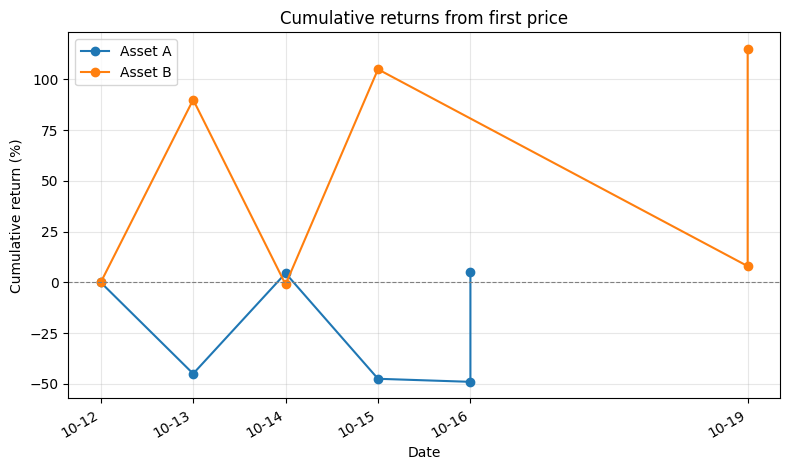

In [64]:
# 在这里导入绘图工具，设置输出目录并绘制累计收益图。
import matplotlib.pyplot as plt  # pyplot绘图接口，简称plt
import matplotlib.dates as mdates  # 日期坐标格式工具，简称mdates

output_dir = base_dir / "outputs"  # 设置图表和CSV的输出文件夹
output_dir.mkdir(parents=True, exist_ok=True)  # 必要时创建目录，已经存在则继续
plot_dates = prices["date"].drop_duplicates().sort_values()  # 本次六个不同的观测日期

fig, ax = plt.subplots(figsize=(8, 4.8))  # fig是整张图，ax是坐标区域；尺寸单位为英寸
for asset, group in prices.groupby("asset"):  # 每轮取一项资产代码和该资产的整张子表
    ax.plot(  # 将这一项资产画成一条折线
        group["date"],  # 横坐标：该资产的日期
        group["cumulative_return"] * 100,  # 纵坐标：只在绘图时转换为百分数数值
        marker="o",  # 用圆点标记每个观测日期
        label=f"Asset {asset}",  # 图例名称，例如Asset A
    )  # 当前资产曲线添加完成

ax.set_title("Cumulative returns from first price")  # 标题说明以首条价格为基准
ax.set_xlabel("Date")  # 横轴名称
ax.set_ylabel("Cumulative return (%)")  # 纵轴名称和百分比单位
ax.set_xticks(plot_dates)  # 明确显示六个观测日期刻度
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))  # 日期刻度简写为月-日
ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)  # 画零累计收益参考线
ax.grid(alpha=0.3)  # 淡色网格，alpha控制透明度
ax.legend()  # 显示每条曲线label对应的图例
fig.autofmt_xdate(rotation=30)  # 旋转日期文字，减少重叠
fig.tight_layout()  # 调整布局，避免标题与轴标签被裁切
fig.savefig(output_dir / "cumulative_returns.png", dpi=150, bbox_inches="tight")  # 保存PNG图片
plt.show()  # 在Notebook中显示图像

## 8. 价格与MA3图

取A子表，画价格和ma3两条线，保留开头缺失，图例为Price与MA3，保存outputs/price_ma3_A.png。


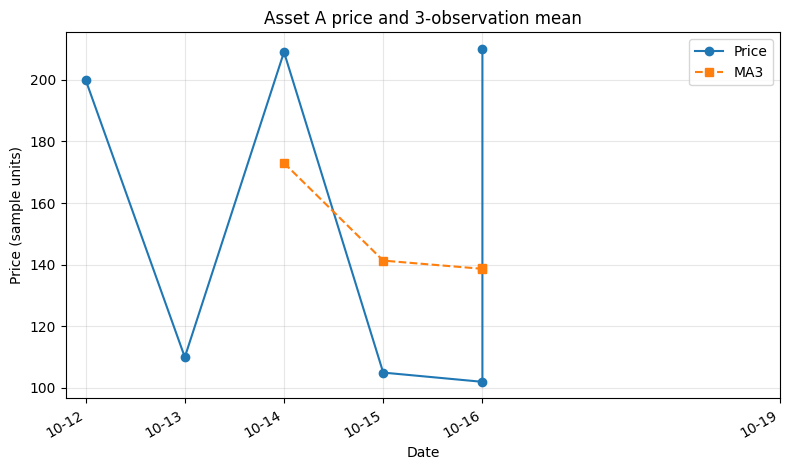

In [65]:
# 均线应该从第几条开始出现：
# 在这里绘图并保存。
a_prices = prices.loc[prices["asset"] == "A"].copy()  # 取出A的六条价格与计算结果
fig, ax = plt.subplots(figsize=(8, 4.8))  # 创建新的独立图像和坐标区域
ax.plot(a_prices["date"], a_prices["price"], marker="o", label="Price")  # 绘制A价格曲线
ax.plot(a_prices["date"], a_prices["ma3"], marker="s", linestyle="--", label="MA3")  # 绘制A三期均线
ax.set_title("Asset A price and 3-observation mean")  # 标题，强调三条观测均值
ax.set_xlabel("Date")  # 横轴为日期
ax.set_ylabel("Price (sample units)")  # 纵轴为样本价格单位
ax.set_xticks(plot_dates)  # 显示本次六个观测日期
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))  # 日期显示为月-日
ax.grid(alpha=0.3)  # 添加淡色网格
ax.legend()  # 显示Price与MA3图例
fig.autofmt_xdate(rotation=30)  # 旋转日期标签
fig.tight_layout()  # 调整边距，避免文字裁切
fig.savefig(output_dir / "price_ma3_A.png", dpi=150, bbox_inches="tight")  # 保存价格均线图
plt.show()  # 在Notebook中显示图像

## 9. 保存与核对

导出returns_and_ma3.csv，预计12行9列。检查A末8%、B末7.5%、MA3前两项缺失、原始收益每组首行仍缺失。


In [70]:
# 在这里保存结果，并输出需要核对的行。
line.to_csv(  # 保存完整计算表
    output_dir / "returns_and_ma3.csv",  # 十二行九列的参考结果
    index=False,  # 不另存默认数字索引
    encoding="utf-8-sig",  # 使用方便Windows识别的编码
    date_format="%Y-%m-%d",  # 日期输出为年-月-日
)  # CSV保存完成
print(line.groupby("asset").tail(1)[["asset", "date", "cumulative_return", "ma3"]])  # 查看各资产末条结果
print(line.shape)  # 预计(12,9)
print("结果文件夹：", output_dir)  # 显示CSV和两张图的保存位置


   asset       date  cumulative_return    ma3
5      A 2026-10-19              0.080  105.0
11     B 2026-10-19              0.075  210.0
(12, 9)
结果文件夹： D:\Learning\study\d14\outputs


## 10. 栈基本操作

使用列表演示append、[-1]、pop，说明哪个会删除元素。手工模拟先放(再放[，应先取出哪个。


In [71]:
# 最后放进去的元素：
# 最先取出的元素：
# 在这里操作一个小栈。
stack_demo = []  # 用空列表表示空栈
stack_demo.append("(")  # 先放入左圆括号
stack_demo.append("[")  # 再放入左方括号，栈顶变成[
print(stack_demo)  # 预计['(', '[']
print(stack_demo[-1])  # 只查看最后一个元素，预计[
opening = stack_demo.pop()  # 取出并删除最后放入的元素，预计[
print("取出的括号：", opening)  # 查看pop的返回值
print("剩下的栈：", stack_demo)  # 预计只剩['(']


['(', '[']
[
取出的括号： [
剩下的栈： ['(']


## 11. 有效括号

独立定义is_valid(s)，遇到左括号入栈，右括号检查栈顶。检查()、()[]{}、([])、{[()]}、([)]、(]、(、)、(((、{[]}。空串为本地选做。


In [72]:
# 手工追踪([])的栈：
# 手工追踪([)]在哪一步失败：
# 在这里独立写函数和样例检查。
def is_valid(s):  # 接收只含()[]{}的字符串，返回括号是否正确配对
    stack = []  # stack是栈，用列表保存尚未匹配的左括号
    pairs = {  # 字典：每种右括号对应它需要的左括号
        ")": "(",  # 右圆括号需要左圆括号
        "]": "[",  # 右方括号需要左方括号
        "}": "{",  # 右花括号需要左花括号
    }  # 对应关系创建完成

    for char in s:  # char是character的缩写，每次读取一个括号字符
        if char in "([{":  # 当前字符是三种左括号之一
            stack.append(char)  # 将左括号加入列表末尾，也就是入栈
        else:  # 原题限定字符集，因此其余字符一定是右括号
            if not stack:  # 空列表为False，not stack表示栈为空
                return False  # 没有等待匹配的左括号，立即判定无效

            opening = stack.pop()  # 取出并删除最后加入的左括号，体现后进先出
            if opening != pairs[char]:  # 取出的左括号必须与当前右括号类型相同
                return False  # 类型不匹配，立即判定无效

    return not stack  # 全部读完后，只有栈为空才有效；这句在for循环外

examples = [  # 每项保存：输入字符串和预期布尔结果
    ("()", True),  # 一对括号
    ("()[]{}", True),  # 多对括号并列
    ("([])", True),  # 正确嵌套
    ("{[()]}", True),  # 三层正确嵌套
    ("([)]", False),  # 数量相等，但关闭顺序错误
    ("(]", False),  # 左右类型不匹配
    ("(", False),  # 还剩未闭合的左括号
    (")", False),  # 没有左括号就遇到右括号
    ("(((", False),  # 多个左括号未闭合
    ("{[]}", True),  # 正确嵌套的花括号与方括号
    ("", True),  # 本地扩展：空串没有未匹配括号；原题长度至少为1
]  # 样例定义完毕

for text, expected in examples:  # 每轮取出一组输入与预期结果
    actual = is_valid(text)  # 调用自己写的括号检查函数
    print(repr(text), "->", actual)  # repr让空串也能清楚显示为引号
    assert actual is expected  # 检查实际布尔结果与预期一致

print("有效括号十一组检查通过。")  # 全部样例通过才输出这句话


'()' -> True
'()[]{}' -> True
'([])' -> True
'{[()]}' -> True
'([)]' -> False
'(]' -> False
'(' -> False
')' -> False
'(((' -> False
'{[]}' -> True
'' -> True
有效括号十一组检查通过。


## 12. 不看参考复写

关闭示例，独立完成累计与MA3、两张图、括号函数；自己的CSV另存outputs/independent_returns_and_ma3.csv。最后回答notes.md。


In [ ]:
# 在这里从空白独立完成。
# 为什么收益需要连乘：
# 为什么MA3开头两条缺失：
